In [ ]:
import numpy as np
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
train = pd.read_csv('/content/train.csv')
test = pd.read_csv('/content/test.csv')
sample = pd.read_csv('/content/sample_submission.csv')

In [ ]:
train.head()

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,42,technician,married,secondary,no,7,no,no,cellular,25,aug,117,3,-1,0,unknown,0
1,1,38,blue-collar,married,secondary,no,514,no,no,unknown,18,jun,185,1,-1,0,unknown,0
2,2,36,blue-collar,married,secondary,no,602,yes,no,unknown,14,may,111,2,-1,0,unknown,0
3,3,27,student,single,secondary,no,34,yes,no,unknown,28,may,10,2,-1,0,unknown,0
4,4,26,technician,married,secondary,no,889,yes,no,cellular,3,feb,902,1,-1,0,unknown,1


In [ ]:
train.nunique()

,0
id,750000
age,78
job,12
marital,3
education,4
default,2
balance,8217
housing,2
loan,2
contact,3


In [ ]:
train = train.dropna()
test = test.dropna()

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 18 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   id         750000 non-null  int64 
 1   age        750000 non-null  int64 
 2   job        750000 non-null  object
 3   marital    750000 non-null  object
 4   education  750000 non-null  object
 5   default    750000 non-null  object
 6   balance    750000 non-null  int64 
 7   housing    750000 non-null  object
 8   loan       750000 non-null  object
 9   contact    750000 non-null  object
 10  day        750000 non-null  int64 
 11  month      750000 non-null  object
 12  duration   750000 non-null  int64 
 13  campaign   750000 non-null  int64 
 14  pdays      750000 non-null  int64 
 15  previous   750000 non-null  int64 
 16  poutcome   750000 non-null  object
 17  y          750000 non-null  int64 
dtypes: int64(9), object(9)
memory usage: 103.0+ MB


In [ ]:
print(train['poutcome'].value_counts())
print(train['marital'].value_counts())
print(train['contact'].value_counts())
print(train['housing'].value_counts())
print(train['education'].value_counts())
print(train['loan'].value_counts())
print(train['default'].value_counts())

poutcome
unknown    672450
failure     45115
success     17691
other       14744
Name: count, dtype: int64
marital
married     480759
single      194834
divorced     74407
Name: count, dtype: int64
contact
cellular     486655
unknown      231627
telephone     31718
Name: count, dtype: int64
housing
yes    411288
no     338712
Name: count, dtype: int64
education
secondary    401683
tertiary     227508
primary       99510
unknown       21299
Name: count, dtype: int64
loan
no     645023
yes    104977
Name: count, dtype: int64
default
no     737151
yes     12849
Name: count, dtype: int64


In [ ]:
train['poutcome'] = train['poutcome'].replace({'unknown':2,'failure':0,'success':1,'other':3})
train['marital'] = train['marital'].replace({'married':1,'divorced':0,'single':1})
train['education'] = train['education'].replace({'primary':1,'tertiary':3,'secondary':2,'unknown':0})
train['housing'] = train['housing'].replace({'yes':1,'no':0})
train['loan'] = train['loan'].replace({'yes':1,'no':0})
train['contact'] = train['contact'].replace({'cellular':1,'telephone':0,'unknown':2})
train['default'] = train['default'].replace({'yes':1,'no':0})

/tmp/ipython-input-460195042.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train['poutcome'] = train['poutcome'].replace({'unknown':2,'failure':0,'success':1,'other':3})
/tmp/ipython-input-460195042.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train['marital'] = train['marital'].replace({'married':1,'divorced':0,'single':1})
/tmp/ipython-input-460195042.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer

In [ ]:
test['poutcome'] = test['poutcome'].replace({'unknown':2,'failure':0,'success':1,'other':3})
test['marital'] = test['marital'].replace({'married':1,'divorced':0,'single':1})
test['education'] = test['education'].replace({'primary':1,'tertiary':3,'secondary':2,'unknown':0})
test['housing'] = test['housing'].replace({'yes':1,'no':0})
test['loan'] = test['loan'].replace({'yes':1,'no':0})
test['contact'] = test['contact'].replace({'cellular':1,'telephone':0,'unknown':2})
test['default'] = test['default'].replace({'yes':1,'no':0})

/tmp/ipython-input-1531245058.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test['poutcome'] = test['poutcome'].replace({'unknown':2,'failure':0,'success':1,'other':3})
/tmp/ipython-input-1531245058.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test['marital'] = test['marital'].replace({'married':1,'divorced':0,'single':1})
/tmp/ipython-input-1531245058.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_

In [ ]:
train.head()

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,42,technician,1,2,0,7,0,0,1,25,aug,117,3,-1,0,2,0
1,1,38,blue-collar,1,2,0,514,0,0,2,18,jun,185,1,-1,0,2,0
2,2,36,blue-collar,1,2,0,602,1,0,2,14,may,111,2,-1,0,2,0
3,3,27,student,1,2,0,34,1,0,2,28,may,10,2,-1,0,2,0
4,4,26,technician,1,2,0,889,1,0,1,3,feb,902,1,-1,0,2,1


In [ ]:
feature_columns = [col for col in train.columns if col not in ['id', 'y']]

X = train[feature_columns]
y = train['y']
X_test = test[feature_columns]

print("Feature and target variables defined.")
print("Columns in X:", X.columns.tolist())
print("Columns in X_test:", X_test.columns.tolist())

Feature and target variables defined.
Columns in X: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']
Columns in X_test: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']


In [ ]:
train.head()


,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,42,technician,1,2,0,7,0,0,1,25,aug,117,3,-1,0,2,0
1,1,38,blue-collar,1,2,0,514,0,0,2,18,jun,185,1,-1,0,2,0
2,2,36,blue-collar,1,2,0,602,1,0,2,14,may,111,2,-1,0,2,0
3,3,27,student,1,2,0,34,1,0,2,28,may,10,2,-1,0,2,0
4,4,26,technician,1,2,0,889,1,0,1,3,feb,902,1,-1,0,2,1


In [ ]:
test.head()

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,750000,32,blue-collar,1,2,0,1397.0,1,0,2,21.0,may,224.0,1.0,-1.0,0.0,2
1,750001,44,management,1,3,0,23.0,1,0,1,3.0,apr,586.0,2.0,-1.0,0.0,2
2,750002,36,self-employed,1,1,0,46.0,1,1,1,13.0,may,111.0,2.0,-1.0,0.0,2
3,750003,58,blue-collar,1,2,0,-1380.0,1,1,2,29.0,may,125.0,1.0,-1.0,0.0,2
4,750004,28,technician,1,2,0,1950.0,1,0,1,22.0,jul,181.0,1.0,-1.0,0.0,2


In [ ]:
X = train.drop(columns=['id','y'])
y = train['y']
X_test = test.drop(columns=['id'])

In [ ]:
# Impute missing values with mean (numerical only)
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)
X_test_imputed = imputer.transform(X_test)

print("Imputation complete.")

Imputation complete.


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed) # Use the imputed data for scaling
X_test_scaled = scaler.transform(X_test_imputed) # Use the imputed data for scaling

print("Scaling complete.")

Scaling complete.


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report

In [ ]:
num_features = X_train.shape[1]
model = Sequential([Dense(128,activation='relu',input_shape=(num_features,)),
                   BatchNormalization(),Dropout(0.3),
                   Dense(64,activation='relu'),BatchNormalization(),Dropout(0.2),
                   Dense(1,activation='sigmoid')])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer=Adam(learning_rate=1e-3),loss='binary_crossentropy',metrics=['AUC'])

In [ ]:
model.fit(X_train,y_train,epochs=10,batch_size=32,validation_data=(X_val,y_val))

Epoch 1/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 77s 4ms/step - AUC: 0.9184 - loss: 0.2234 - val_AUC: 0.9563 - val_loss: 0.1685
Epoch 2/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 67s 3ms/step - AUC: 0.9490 - loss: 0.1777 - val_AUC: 0.9578 - val_loss: 0.1650
Epoch 3/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 81s 3ms/step - AUC: 0.9517 - loss: 0.1733 - val_AUC: 0.9587 - val_loss: 0.1627
Epoch 4/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 60s 3ms/step - AUC: 0.9528 - loss: 0.1708 - val_AUC: 0.9589 - val_loss: 0.1615
Epoch 5/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 99s 4ms/step - AUC: 0.9528 - loss: 0.1703 - val_AUC: 0.9591 - val_loss: 0.1611
Epoch 6/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 66s 3ms/step - AUC: 0.9535 - loss: 0.1698 - val_AUC: 0.9598 - val_loss: 0.1617
Epoch 7/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 80s 4ms/step - AUC: 0.9548 - loss: 0.1678 - val_AUC: 0.9600 - val_loss: 0.1613
Epoch 8/10
18750/18750 ━━━━━━━━━━━━━━━━━━━━ 79s 4ms/step - AUC: 0.9545 - loss: 0.1674 - val_AUC: 0.9602 - val_loss: 0.1605
Epoch 9/10
18750

4688/4688 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step


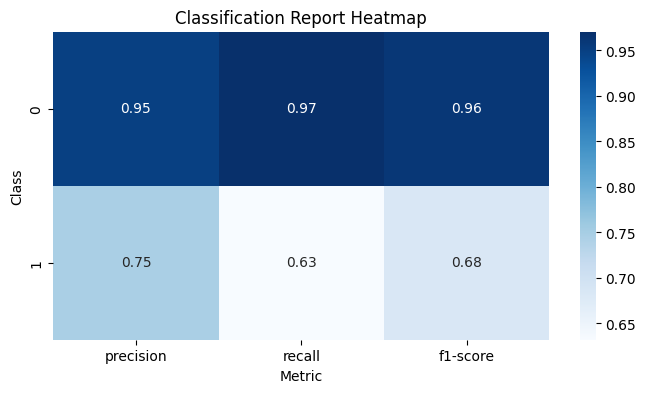

In [ ]:
y_val_pred_proba = model.predict(X_val)
y_val_pred = (y_val_pred_proba > 0.5).astype(int)

report_dict = classification_report(y_val, y_val_pred, output_dict=True)

report_df = pd.DataFrame(report_dict).transpose()

# Plot heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(report_df.iloc[:2, :3], annot=True, fmt=".2f", cmap="Blues")
plt.title("Classification Report Heatmap")
plt.ylabel("Class")
plt.xlabel("Metric")
plt.show()


In [ ]:
y_test_pred_proba = model.predict(X_test_scaled)
y_test_pred_binary = (y_test_pred_proba > 0.5).astype(int)

3440/3440 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step


In [ ]:
submission = test.copy()
submission['y'] = y_test_pred_binary
submission = submission[['id','y']]
submission['y'] = submission['y']
submission.to_csv("submission.csv", index=False)
print("\nSaved submission.csv successfully!")


Saved submission.csv successfully!


In [ ]:
submission.head(20)

,id,y
0,750000,0
1,750001,0
2,750002,0
3,750003,0
4,750004,0
5,750005,0
6,750006,0
7,750007,0
8,750008,0
9,750009,0
